# Recursividad · Trazas y fractales

Pila de llamadas, árboles de llamadas y figuras recursivas (dibujadas con `matplotlib` en lugar de PythonG).

## 1. Pila de llamadas de `factorial(5)`

Mostrar cómo crece y se vacía la pila de llamadas al calcular `factorial(5)`.

In [1]:
def factorial(n, nivel=0):
    print("  " * nivel + f"llama factorial({n})")
    resultado = 1 if n == 0 else n * factorial(n - 1, nivel + 1)
    print("  " * nivel + f"factorial({n}) devuelve {resultado}")
    return resultado

factorial(5)

llama factorial(5)
  llama factorial(4)
    llama factorial(3)
      llama factorial(2)
        llama factorial(1)
          llama factorial(0)
          factorial(0) devuelve 1
        factorial(1) devuelve 1
      factorial(2) devuelve 2
    factorial(3) devuelve 6
  factorial(4) devuelve 24
factorial(5) devuelve 120


## 2. ¿Qué comparación es?

¿Qué calcula esta función recursiva sobre naturales? Devuelve `True` si `a < b`.

In [2]:
def comparacion(a, b):
    if b == 0:
        return False
    elif a == 0:
        return True
    return comparacion(a - 1, b - 1)

print(all(comparacion(a, b) == (a < b) for a in range(20) for b in range(20)))

True


## 3. Árbol de llamadas de `bits(63)`

Dibujar el árbol de llamadas de una función recursiva que cuenta los bits de un número (`bits(n) = 1 + bits(n // 2)`).

In [3]:
def bits(n, nivel=0):
    print("  " * nivel + f"bits({n})")
    return 1 if n < 2 else 1 + bits(n // 2, nivel + 1)

print(bits(63))

bits(63)
  bits(31)
    bits(15)
      bits(7)
        bits(3)
          bits(1)
6


## 4. Árbol de llamadas de Fibonacci

Dibujar el árbol de llamadas de `fibonacci(5)` y modificar la función para que anuncie el inicio y el final de cada cálculo. Probarlo con el cuarto y el décimo término y contar las llamadas.

In [4]:
def fibonacci(n, nivel=0, contador=None, verbose=True):
    if contador is not None:
        contador[0] += 1
    if verbose:
        print("  " * nivel + f"Empieza cálculo de Fibonacci de {n}")
    m = 1 if n <= 2 else fibonacci(n - 1, nivel + 1, contador, verbose) + fibonacci(n - 2, nivel + 1, contador, verbose)
    if verbose:
        print("  " * nivel + f"Acaba cálculo de Fibonacci de {n} y devuelve el valor {m}")
    return m

fibonacci(4)
contador = [0]
print(fibonacci(10, contador=contador, verbose=False), "con", contador[0], "llamadas")

Empieza cálculo de Fibonacci de 4
  Empieza cálculo de Fibonacci de 3
    Empieza cálculo de Fibonacci de 2
    Acaba cálculo de Fibonacci de 2 y devuelve el valor 1
    Empieza cálculo de Fibonacci de 1
    Acaba cálculo de Fibonacci de 1 y devuelve el valor 1
  Acaba cálculo de Fibonacci de 3 y devuelve el valor 2
  Empieza cálculo de Fibonacci de 2
  Acaba cálculo de Fibonacci de 2 y devuelve el valor 1
Acaba cálculo de Fibonacci de 4 y devuelve el valor 3
55 con 109 llamadas


## 5. Traza de `mcd(323, 323)`

In [5]:
def mcd(a, b, nivel=0):
    print("  " * nivel + f"mcd({a}, {b})")
    return a if b == 0 else mcd(b, a % b, nivel + 1)

print(mcd(323, 323))

mcd(323, 323)
  mcd(323, 0)
323


## 6. Bisección recursiva

Implementar el método de la bisección de forma recursiva.

In [6]:
def biseccion(f, a, b, epsilon=1e-9):
    c = (a + b) / 2
    if b - a < epsilon or f(c) == 0:
        return c
    return biseccion(f, a, c, epsilon) if f(a) * f(c) < 0 else biseccion(f, c, b, epsilon)

print(biseccion(lambda x: x**2 - 2, 0, 2))

1.4142135619185865


## 7. Torres de Hanói gráficas

Mostrar gráficamente la resolución de las torres de Hanói y dibujar el árbol de llamadas de `resuelve_hanoi(4, 1, 3, 2)`.

resuelve_hanoi(4, 1, 3, 2)
  resuelve_hanoi(3, 1, 2, 3)
    resuelve_hanoi(2, 1, 3, 2)
      resuelve_hanoi(1, 1, 2, 3)
        resuelve_hanoi(0, 1, 3, 2)
        resuelve_hanoi(0, 3, 2, 1)
      resuelve_hanoi(1, 2, 3, 1)
        resuelve_hanoi(0, 2, 1, 3)
        resuelve_hanoi(0, 1, 3, 2) 
... 31 llamadas


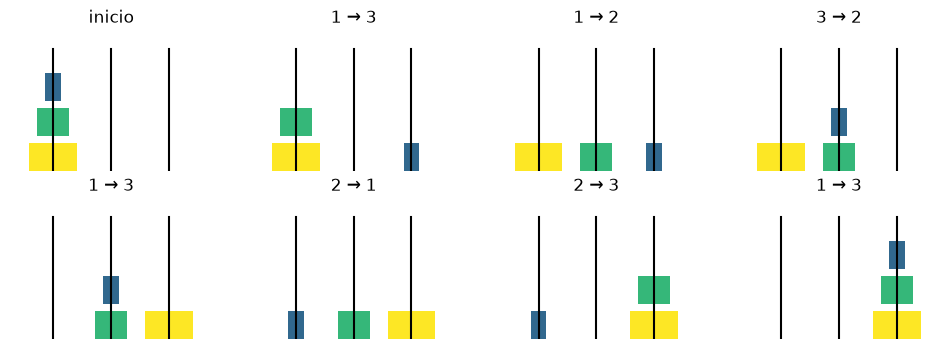

In [7]:
import matplotlib.pyplot as plt

def resuelve_hanoi(n, origen, destino, auxiliar, movimientos, nivel=0, arbol=None):
    if arbol is not None:
        arbol.append("  " * nivel + f"resuelve_hanoi({n}, {origen}, {destino}, {auxiliar})")
    if n == 0:
        return
    resuelve_hanoi(n - 1, origen, auxiliar, destino, movimientos, nivel + 1, arbol)
    movimientos.append((origen, destino))
    resuelve_hanoi(n - 1, auxiliar, destino, origen, movimientos, nivel + 1, arbol)

arbol = []
resuelve_hanoi(4, 1, 3, 2, [], arbol=arbol)
print("\n".join(arbol[:9]), "\n...", len(arbol), "llamadas")

n, movimientos = 3, []
resuelve_hanoi(n, 1, 3, 2, movimientos)
torres = {1: list(range(n, 0, -1)), 2: [], 3: []}
fig, ejes = plt.subplots(2, 4, figsize=(12, 4))
for paso, eje in enumerate(ejes.flat):
    for t in (1, 2, 3):
        eje.plot([t * 4, t * 4], [0, n + 0.5], color="black")
        for altura, disco in enumerate(torres[t]):
            eje.barh(altura + 0.4, disco * 1.1, left=t * 4 - disco * 0.55, height=0.8, color=plt.cm.viridis(disco / n))
    eje.set(xlim=(1, 15), ylim=(0, n + 1))
    eje.set_title("inicio" if paso == 0 else f"{movimientos[paso - 1][0]} → {movimientos[paso - 1][1]}")
    eje.axis("off")
    if paso < len(movimientos):
        o, d = movimientos[paso]
        torres[d].append(torres[o].pop())
plt.show()

## 8. Curva de von Koch y variantes

Dibujar la curva de von Koch (cada segmento se divide en tres y el central se sustituye por dos lados de un triángulo) y probar a cambiar los parámetros con los que se calcula el pico.

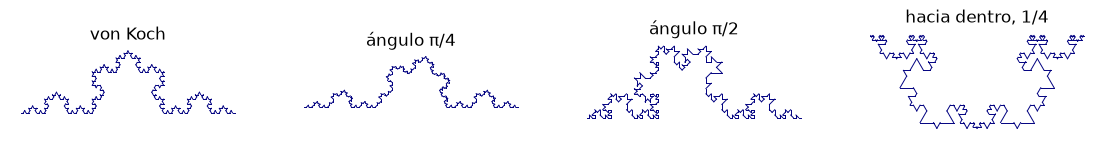

In [8]:
from math import cos, pi, sin

def koch(xa, ya, xb, yb, nivel, segmentos, angulo=pi / 3, fraccion=1 / 3):
    if nivel == 0:
        segmentos.append(((xa, xb), (ya, yb)))
        return
    xc, yc = xa + (xb - xa) * fraccion, ya + (yb - ya) * fraccion
    xd, yd = xb + (xa - xb) * fraccion, yb + (ya - yb) * fraccion
    # pico: rota el segmento central alrededor de c
    xe = xc + (xd - xc) * cos(angulo) - (yd - yc) * sin(angulo)
    ye = yc + (xd - xc) * sin(angulo) + (yd - yc) * cos(angulo)
    for p, q in (((xa, ya), (xc, yc)), ((xc, yc), (xe, ye)), ((xe, ye), (xd, yd)), ((xd, yd), (xb, yb))):
        koch(*p, *q, nivel - 1, segmentos, angulo, fraccion)

fig, ejes = plt.subplots(1, 4, figsize=(14, 3))
for eje, (angulo, fraccion, titulo) in zip(ejes, ((pi / 3, 1 / 3, "von Koch"), (pi / 4, 1 / 3, "ángulo π/4"),
                                                  (pi / 2, 1 / 3, "ángulo π/2"), (-pi / 3, 0.25, "hacia dentro, 1/4"))):
    segmentos = []
    koch(0, 0, 1, 0, 4, segmentos, angulo, fraccion)
    for xs, ys in segmentos:
        eje.plot(xs, ys, color="navy", linewidth=0.7)
    eje.set_title(titulo)
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()

## 9. Curva dragón

La curva dragón de nivel 0 es un segmento; la de nivel $n$ entre $a$ y $b$ se forma con dos curvas de nivel $n-1$: de $a$ a $c$ y de $b$ a $c$, con $c = \left(\frac{x_a+x_b+y_a-y_b}{2}, \frac{x_b-x_a+y_a+y_b}{2}\right)$.

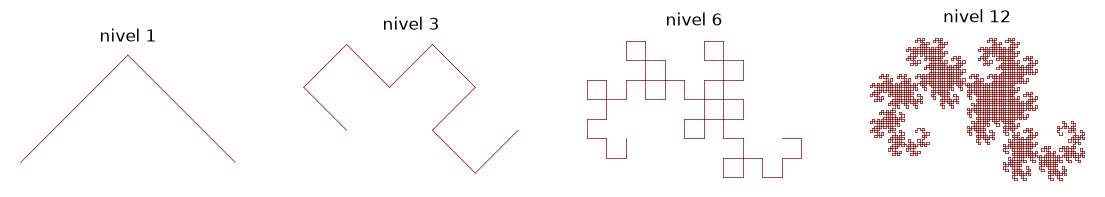

In [9]:
def dragon(xa, ya, xb, yb, nivel, segmentos):
    if nivel == 0:
        segmentos.append(((xa, xb), (ya, yb)))
        return
    xc, yc = (xa + xb + ya - yb) / 2, (xb - xa + ya + yb) / 2
    dragon(xa, ya, xc, yc, nivel - 1, segmentos)
    dragon(xb, yb, xc, yc, nivel - 1, segmentos)

fig, ejes = plt.subplots(1, 4, figsize=(14, 3))
for eje, nivel in zip(ejes, (1, 3, 6, 12)):
    segmentos = []
    dragon(0, 0, 1, 0, nivel, segmentos)
    for xs, ys in segmentos:
        eje.plot(xs, ys, color="darkred", linewidth=0.5)
    eje.set_title(f"nivel {nivel}")
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()

## 10. Triángulo de Sierpinski

En cada nivel, cada triángulo se divide en tres triángulos con los puntos medios de sus lados.

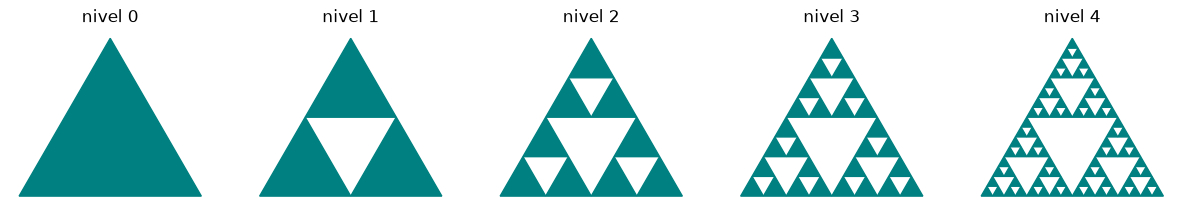

In [10]:
def sierpinski(a, b, c, nivel, triangulos):
    if nivel == 0:
        triangulos.append((a, b, c))
        return
    ab, bc, ca = [((p[0] + q[0]) / 2, (p[1] + q[1]) / 2) for p, q in ((a, b), (b, c), (c, a))]
    sierpinski(a, ab, ca, nivel - 1, triangulos)
    sierpinski(ab, b, bc, nivel - 1, triangulos)
    sierpinski(ca, bc, c, nivel - 1, triangulos)

fig, ejes = plt.subplots(1, 5, figsize=(15, 3))
for nivel, eje in enumerate(ejes):
    triangulos = []
    sierpinski((0, 0), (1, 0), (0.5, 0.866), nivel, triangulos)
    for t in triangulos:
        eje.fill(*zip(*t), color="teal")
    eje.set_title(f"nivel {nivel}")
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()

## 11. Curva de Hilbert

Dibujar la curva de relleno del espacio de Hilbert para un nivel de recursión dado.

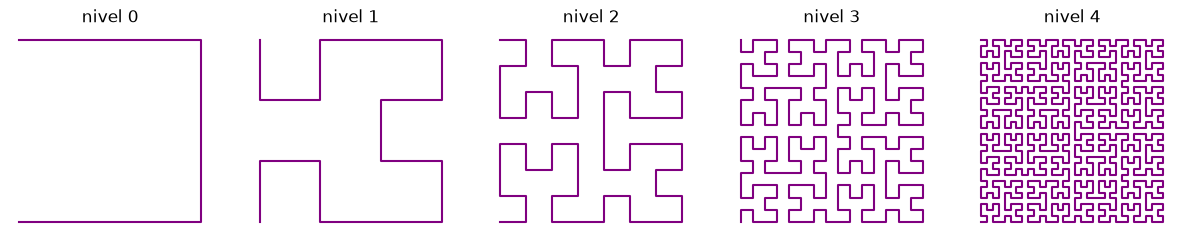

In [11]:
def hilbert(nivel, x=0.0, y=0.0, xi=1.0, xj=0.0, yi=0.0, yj=1.0, puntos=None):
    # (xi, xj) y (yi, yj) son los ejes del cuadrado actual
    if puntos is None:
        puntos = []
    if nivel == 0:
        puntos.append((x + (xi + yi) / 2, y + (xj + yj) / 2))
        return puntos
    hilbert(nivel - 1, x, y, yi / 2, yj / 2, xi / 2, xj / 2, puntos)
    hilbert(nivel - 1, x + xi / 2, y + xj / 2, xi / 2, xj / 2, yi / 2, yj / 2, puntos)
    hilbert(nivel - 1, x + xi / 2 + yi / 2, y + xj / 2 + yj / 2, xi / 2, xj / 2, yi / 2, yj / 2, puntos)
    hilbert(nivel - 1, x + xi / 2 + yi, y + xj / 2 + yj, -yi / 2, -yj / 2, -xi / 2, -xj / 2, puntos)
    return puntos

fig, ejes = plt.subplots(1, 5, figsize=(15, 3))
for nivel, eje in enumerate(ejes):
    eje.plot(*zip(*hilbert(nivel + 1)), color="purple")
    eje.set_title(f"nivel {nivel}")
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()

## 12. Árboles recursivos

Un árbol es un tronco del que salen dos árboles más pequeños girados. Dibujar árboles regulares y, después, con ángulo y proporción rama/tronco aleatorios para que parezcan más naturales.

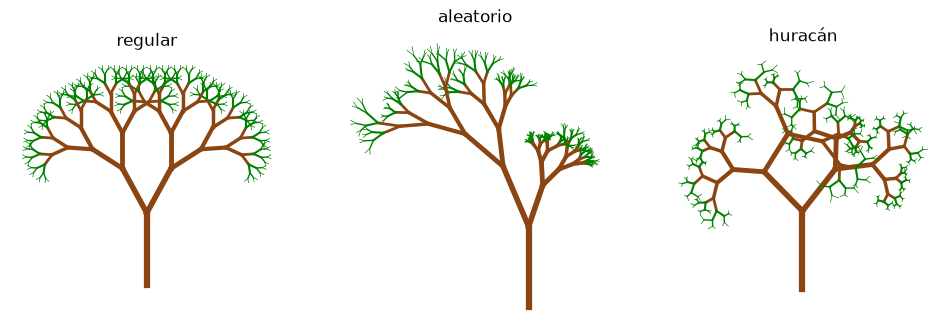

In [12]:
import random

def arbol(x, y, angulo, longitud, nivel, segmentos, giro=0.5, proporcion=0.7, azar=None):
    if nivel == 0:
        return
    x2, y2 = x + longitud * cos(angulo), y + longitud * sin(angulo)
    segmentos.append(((x, x2), (y, y2), nivel))
    for signo in (-1, 1):
        g = giro * (azar.uniform(0.5, 1.5) if azar else 1)
        p = proporcion * (azar.uniform(0.7, 1.2) if azar else 1)
        arbol(x2, y2, angulo + signo * g, longitud * p, nivel - 1, segmentos, giro, proporcion, azar)

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
for eje, (titulo, azar, giro) in zip(ejes, (("regular", None, 0.5), ("aleatorio", random.Random(7), 0.4),
                                            ("huracán", random.Random(3), 0.9))):
    segmentos = []
    arbol(0, 0, pi / 2, 1, 9, segmentos, giro=giro, azar=azar)
    for xs, ys, nivel in segmentos:
        eje.plot(xs, ys, color="saddlebrown" if nivel > 3 else "green", linewidth=nivel / 2)
    eje.set_title(titulo)
    eje.set_aspect("equal")
    eje.axis("off")
plt.show()